## Ejercicio 1.1: 
Entradas y conteos

### a) 
Una permutación uniforme de tamaño 𝑛 es una lista elegida al azar entre las 𝑛! permutaciones de 0,...,𝑛 −1, todas con la misma probabilidad. Con la función del código base que genera permutaciones uniformes, genere 6000 permutaciones de tamaño 𝑛 = 3 y arme una tabla con la frecuencia de cada una de las 6 posibles.

In [89]:
# Imports
import json
import numpy as np
from codigo_base import *

# Variables globales
rng = np.random.default_rng(4)

In [90]:
N = 6000   
posiblesPermutaciones = [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]
# Armamos la lista de permutaciones
frecuenciaPermutaciones = [0] * 6

# Contamos la frecuencia de cada permutación
for i in range (N):
    permutacion = permutacion_aleatoria(3, rng)
    frecuenciaPermutaciones[posiblesPermutaciones.index(permutacion)] += 1
    
print(frecuenciaPermutaciones)

[1003, 1021, 966, 983, 995, 1032]


In [91]:
# Calculamos varianza muestral
# ddof=1 asegura que sea la varianza muestral (divide por n - 1)
varianza_muestral = np.var(frecuenciaPermutaciones, ddof=1)

print(varianza_muestral)

588.8


i) ¿Qué distribución tiene la frecuencia de una permutación fija?

La distribucion de la frecuencia de una permutacion fija es una binomial. Lo podemos pensar como la probabilidad de que salga justo esa permutacion en los N=6000 ensayos con $p = 1/6$.

In [92]:
desvioEstandar1000 = np.sqrt(1000*(1/6)*(5/6))
desvioEstandar6000 = np.sqrt(6000*(1/6)*(5/6))
print("Desvio con N = 1000: ", desvioEstandar1000)
print("Desvio con N = 6000: ", desvioEstandar6000)

Desvio con N = 1000:  11.785113019775793
Desvio con N = 6000:  28.867513459481287


ii) ¿De qué tamaño esperaría que fueran sus diferencias con 1000?

La diferencia respecto a N=6000 es menor. 

In [93]:
diferencias = [0]*6
for i in range (6):
    diferencias[i] = abs(N/6 - frecuenciaPermutaciones[i])

print("Desvio real para N = 6000: ", diferencias)

Desvio real para N = 6000:  [3.0, 21.0, 34.0, 17.0, 5.0, 32.0]


iii) ¿Lo observado es compatible con que las 6 sean equiprobables?

Lo observado es compatible con que las 6 sean equiprobables. Al dejar una permutacion fija y preguntarse cuántas veces salió, tenemos un experimento de Bernouli (salió o no salió) con probabilidad 1/6. A lo largo de las N tiradas la suma de los aciertos sigue la distribucion de la binomial. 

Tambien observamos que e desvio real para N=6000 no supera en ningun caso a $2*\sigma$

### b)
Los algoritmos son deterministas. Explique por qué, aun así, 𝑆𝑛, 𝐶𝑛 y 𝑄𝑛 son variables aleatorias. Con los conteos del experimento uniforme, determine cuáles de los siguientes conteos varían de una lista a otra y cuáles son constantes: swaps y comparaciones de insertion sort, swaps y comparaciones de selection sort, comparaciones de quicksort. 



i) ¿Por qué son constantes?

$S_n, C_n$ y $Q_n$ son variables aleatorias debido a que su valor depende del input, que es una lista que se genera de una variable aleatoria. Citando a la consigna tenemos que "El azar entra por la entrada: si la lista a ordenar es elegida al azar, la cantidad de operaciones es una variable aleatoria"

Para ver cuales conteos varían, vamos a analizar la varianza muestral de estos conteos.

In [94]:
conteos = open("conteos.jsonl","r")

cantUniformes = 0
insertionSort = ([],[])
selectionSort = ([],[])
quickSort = []

# Buscamos todos los datos que necesitamos
for linea in conteos:
    datos = json.loads(linea)
    if datos["experimento"] == "uniforme":
        cantUniformes += 1
        if datos["algoritmo"] == "insertion":
            insertionSort[0].append(datos["swaps"])
            insertionSort[1].append(datos["comparaciones"])

        if datos["algoritmo"] == "selection":
            selectionSort[0].append(datos["swaps"])
            selectionSort[1].append(datos["comparaciones"])

        if datos["algoritmo"] == "quick_primero":
            quickSort.append(datos["comparaciones"])


varInsertionSwaps = np.var(insertionSort[0], ddof=1)
varInsertionComparaciones = np.var(insertionSort[1], ddof=1)
varSelectionSwaps = np.var(selectionSort[0], ddof=1)
varSelectionComparaciones = np.var(selectionSort[1], ddof=1)
varQuickPrimeroComparaciones = np.var(quickSort, ddof=1)

print("Varianza Insertion Sort Swaps: ", varInsertionSwaps)
print("Varianza Insertion Sort Comparaciones: ", varInsertionComparaciones)
print("Varianza Selection Sort Swaps: ", varSelectionSwaps)
print("Varianza Selection Sort Comparaciones: ", varSelectionComparaciones)
print("Varianza Quick Sort Primero Comparaciones: ", varQuickPrimeroComparaciones)

Varianza Insertion Sort Swaps:  27508.54618084042
Varianza Insertion Sort Comparaciones:  27418.472333916958
Varianza Selection Sort Swaps:  3.4130262631315653
Varianza Selection Sort Comparaciones:  0.0
Varianza Quick Sort Primero Comparaciones:  3532.4710652826416


ii) ¿Cuáles son constantes y cuales varían?

La varianza muestral de las comparaciones del selection sort es nula y la de los swaps es muy pequeña, esto significa que la primera es constante y la segunda es prácticamente constante. Tomamos la varianza muestral y confiamos en los resultados debido a que la cantidad de datos utilizados es grande.

iii) Justifique el valor de los conteos constantes. ¿Puede un conteo ser constante aunque la entrada sea aleatoria?

Si porque la cantidad de comparaciones depende del tamaño de la entrada y no de que tan desordenada este la lista. La cantidad de swaps depende de si tienen la misma cantidad de elementod desordenados que ordenados, por lo que si son similares, la varianza es baja.

### c) 

Con los conteos del experimento desorden, ¿qué valores toman $𝑆_{100}$, $𝐶_{100}$ y $𝑄_{100}$ sobre la lista ya ordenada (𝑘 = 0)? ¿Son variables aleatorias? Compare el valor de $𝑄_{100}$ con los que se obtienen sobre permutaciones uniformes.

In [95]:
lista_Ordenada = lista_desordenada(100, 0, rng)

S_100, C_100 = insertion_sort(lista_Ordenada)
_, Q_100 = quicksort(lista_Ordenada)

print("Swaps Insertion sort (S_100): ", S_100)
print("Comparaciones Insertion sort (C_100): ", C_100)
print("Comparaciones Quick sort (Q_100): ", Q_100)

Swaps Insertion sort (S_100):  0
Comparaciones Insertion sort (C_100):  99
Comparaciones Quick sort (Q_100):  4950


i) ¿Son variables aleatorias?

No, no son variables aleatorias. Recordemos que la aleatoreidad de las variables venía de lo aleatorio en el orden de las listas. Al fijar la lista, se pierde la aleatoreidad.

ii) Compare el valor de $𝑄_{100}$ con los que se obtienen sobre permutaciones uniformes.

In [96]:
lista_desordenada_uniforme = permutacion_aleatoria(100, rng)
comparacionesQuickSort = 0

for i in range (1000):
    _, Q_100 = quicksort(lista_desordenada_uniforme)
    comparacionesQuickSort += Q_100
mediaQ100Uniforme = comparacionesQuickSort / 1000
print("Media muestral omparaciones Quick sort (Q_100) para n=1000: ", mediaQ100Uniforme)

Media muestral omparaciones Quick sort (Q_100) para n=1000:  613.0


Como $Q_{100}$ para una lista uniforme sí es una variable aleatoria, calculamos su valor para 1000 experimentos y tomamos la media muestral.
El valor de $Q_{100}$ para listas uniformes es unas 8 veces más chico que para la lista ordenada.

## Ejercicio 1.2: 
Descripción de $S_{100}$ y $Q_{100}$. Con las $N = 2000$ listas del experimento uniforme:

### a) 
Muestre las distribuciones de $S_{100}$ y de $Q_{100}$ con histogramas, diagramas de caja y gráficos cuantil-cuantil contra la normal. Calcule media, desvío estándar, mediana, intervalo intercuartil y coeficiente de asimetría $\hat{\gamma}$.

i) Graficos. Por cada tipo de grafo, armamos una figura que contenga el gráfico de cáda V.A. A la izquierda $S_{100}$, a la derecha $Q_{100}$

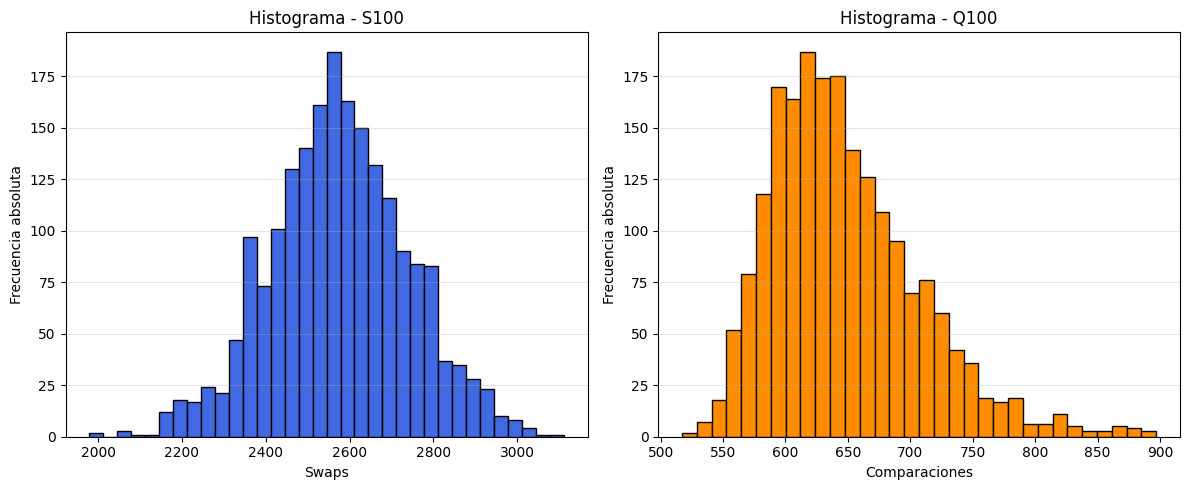

In [ ]:
import matplotlib.pyplot as plt

# Creamos la figura y los subgráficos (1 fila, 2 columnas)
figura, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de S100 (Panel izquierdo)
columna1.hist(insertionSort[1], bins='auto', color='royalblue', edgecolor='black')
columna1.set_title('Histograma - S100')
columna1.set_xlabel('Swaps')
columna1.set_ylabel('Frecuencia absoluta')
columna1.grid(axis='y', alpha=0.3)

# Histograma de Q100 (Panel derecho)
columna2.hist(quickSort, bins='auto', color='darkorange', edgecolor='black')
columna2.set_title('Histograma - Q100')
columna2.set_xlabel('Comparaciones')
columna2.set_ylabel('Frecuencia absoluta')
columna2.grid(axis='y', alpha=0.3)

# Ajustar el diseño y mostrar
plt.tight_layout() # Evita que los márgenes y títulos se superpongan
plt.show()

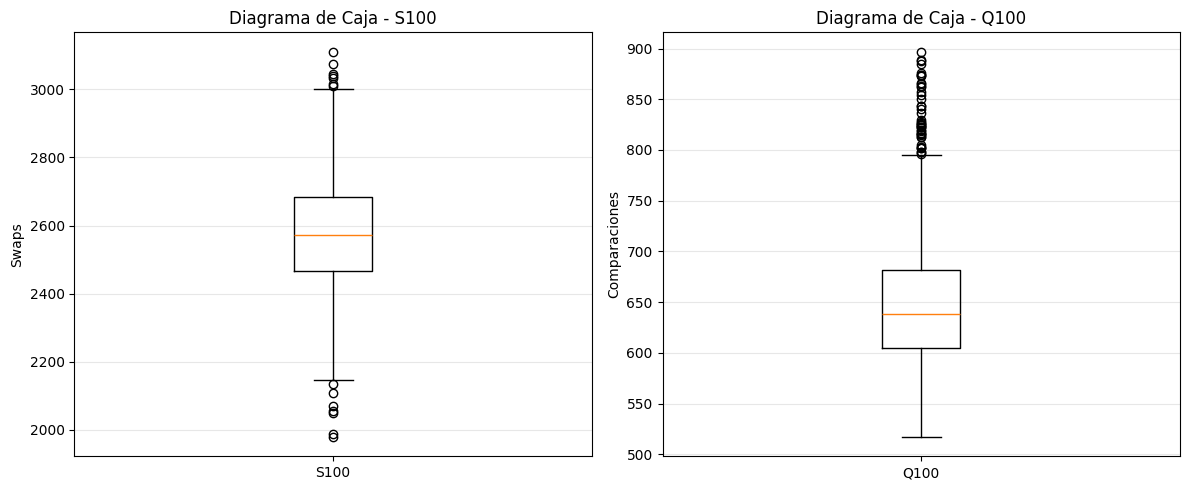

In [98]:
import matplotlib.pyplot as plt

# Creamos la figura con 1 fila y 2 columnas
fig, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Boxplot de S100 (Panel izquierdo)
columna1.boxplot(insertionSort[1])
columna1.set_title('Diagrama de Caja - S100')
columna1.set_ylabel('Swaps')
columna1.set_xticks([1])
columna1.set_xticklabels(['S100'])
columna1.grid(axis='y', alpha=0.3)

# 2. Boxplot de Q100 (Panel derecho)
columna2.boxplot(quickSort)
columna2.set_title('Diagrama de Caja - Q100')
columna2.set_ylabel('Comparaciones')
columna2.set_xticks([1])
columna2.set_xticklabels(['Q100'])
columna2.grid(axis='y', alpha=0.3)

# Ajustamos y mostramos
plt.tight_layout()
plt.show()

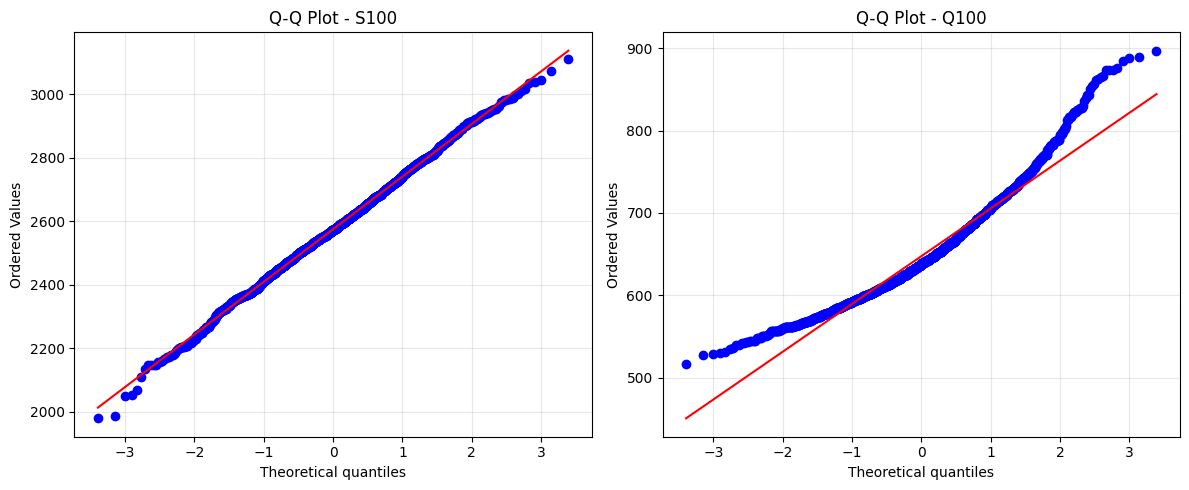

In [100]:
import scipy.stats as stats

# Creamos la figura con 1 fila y 2 columnas
fig, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Q-Q plot para S100 (Panel izquierdo)
stats.probplot(insertionSort[1], dist="norm", plot=columna1)
columna1.set_title('Q-Q Plot - S100')
columna1.grid(alpha=0.3)

# 2. Q-Q plot para Q100 (Panel derecho)
stats.probplot(quickSort, dist="norm", plot=columna2)
columna2.set_title('Q-Q Plot - Q100')
columna2.grid(alpha=0.3)

# Ajustamos y mostramos
plt.tight_layout()
plt.show()

ii) Calcule media, desvío estándar, mediana, intervalo intercuartil y coeficiente de asimetría $\hat{\gamma}$.

In [102]:
import numpy as np
import scipy.stats as stats

def imprimir_estadisticos(datos, nombre_variable):
    # Cálculos
    media = np.mean(datos)
    # ddof=1 calcula el desvío estándar muestral (divide por n-1 en lugar de n)
    desvio = np.std(datos, ddof=1) 
    mediana = np.median(datos)
    iqr = stats.iqr(datos)
    # bias=False ajusta el sesgo de la asimetría para muestras
    asimetria = stats.skew(datos, bias=False) 
    
    # Impresión en pantalla
    print(f"--- Estadísticos de {nombre_variable} ---")
    print(f"Media:                      {media:.4f}")
    print(f"Desvío Estándar:            {desvio:.4f}")
    print(f"Mediana:                    {mediana:.4f}")
    print(f"Intervalo Intercuartil:     {iqr:.4f}")
    print(f"Coef. Asimetría (γ̂):        {asimetria:.4f}")
    print("-" * 40 + "\n")

# Ejecutás la función para tus dos variables
imprimir_estadisticos(insertionSort[1], "S100")
imprimir_estadisticos(quickSort, "Q100")

--- Estadísticos de S100 ---
Media:                      2574.9265
Desvío Estándar:            165.5852
Mediana:                    2573.0000
Intervalo Intercuartil:     215.0000
Coef. Asimetría (γ̂):        -0.0228
----------------------------------------

--- Estadísticos de Q100 ---
Media:                      647.3545
Desvío Estándar:            59.4346
Mediana:                    638.0000
Intervalo Intercuartil:     76.2500
Coef. Asimetría (γ̂):        0.9409
----------------------------------------



### b) 
En la definición de $\gamma_X$, ¿por qué se eleva al cubo y no al cuadrado? ¿Por qué se divide por $\sigma^3$? ¿Cuánto vale $\gamma_X$ si la distribución de $X$ es simétrica alrededor de su media?

Definición de $\gamma_X = E \left[ \left( \frac{X-\mu}{\sigma}\right)^3  \right]$

i) ¿por qué se eleva al cubo y no al cuadrado?
Se eleva al cubo para no perder el signo. La gracia del coeficiente de asimetría es que te dice si los valores se distribuyen de manera simétrica o si algúna cola concentra más valores, y te dice cuál. Si elevasemos al cuadrado, todos los nuemros quedan positivos, perdiendo esa información.

ii) ¿Por qué se divide por $\sigma^3$?
Se divide por $\sigma^3$ para estandarizar el resultado. Esto le quita las unidades de medida (si las tiene) y lo hace independiente de la escala. Supongamos que medimos algo en milisegundos y otra en nanosegundos. Al usar el tercer momento, nos queda $ms^3$ en el primero, y $ns^3$ en el segundo. Como el $\sigma$ también contiene la unidad, al dividir se cancelan las unidades. Por otro lado, si no dividiéramos, el coeficiente de asimetría para el primero daría un número numéricamente mucho más grande que el segundo, pero no porque necesariamente esté mas deformado.

iii) ¿Cuánto vale $\gamma_X$ si la distribución de $X$ es simétrica alrededor de su media?
Si la distribución es simétrica, entonces $\gamma_X = 0$

### 3)
¿Qué diferencias de forma observa entre $S_{100}$ y $Q_{100}$? ¿Es consistente la posición relativa de la media y la mediana con el valor de $\hat{\gamma}$? ¿Alguna de las dos distribuciones se parece a una conocida?

i) $S_{100}$ tiene un histograma que a simple vista parece simétrico. Sin embargo el histograma de $Q_{100}$ parece estar un poco más deformado, hay más valores concentrados a la izquierda, y una cola más larga y chata a la derecha.

ii) Sí, es consistente. Para $S_{100}$ la media y la mediana se encuentran muy centradas en el histograma, casi espejando un lado y el otro. Su coeficiente de asimetría es casi 0, reflejando que la distribución es prácticamente normal. 
Por otro lado, para $Q_{100}$, la media y la mediana se encuentrn corridas hacia la izquierda, donde se concentran la mayoría de los valores. Nuevamente es consistente con el coeficiente de asimetría que es casi 1. Recordemos que un $\hat{\gamma}>0$ indica una cola derecha más larga y los datos concentrados en valores más bajos. Justo como es el caso.

iii) Sí, $S_{100}$ es prácticamente una normal. $Q_{100}$ podría ser una gamma?